# pr5 · Singular Value Decomposition (SVD)
$A = U S V^t$, $\;U \in \mathbb{R}^{m\times m}$, $V \in \mathbb{R}^{n\times n}$ orthogonal, $S$ diagonal with $\sigma_1 \ge \dots \ge 0$.

In [1]:
import numpy as np, scipy.linalg as sla, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
eps = np.finfo(float).eps

A_notes = np.array([[3., 0], [4, 5]])        # Example 6.1.1 of the notes
A_rect = rng.standard_normal((5, 3))         # a rectangular test matrix

## Ex.1 · SVD from the eigen-decompositions of $A^tA$ and $AA^t$
As in §6.1 of the notes: $A^tA = V\Lambda V^t$, $\sigma_k = \sqrt{\lambda_k}$, $u_k = Av_k/\sigma_k$.
The remaining columns of $U$ ($k > r$) are eigenvectors of $AA^t$ with eigenvalue 0.

In [2]:
def svd_eig(A, tol=None):
    A = np.asarray(A, float); m, n = A.shape
    lam, V = np.linalg.eigh(A.T @ A)                   # eigenpairs of A^t A (ascending)
    idx = np.argsort(lam)[::-1]; lam, V = lam[idx], V[:, idx]
    s = np.sqrt(np.clip(lam, 0, None))
    tol = max(m, n) * eps * s[0] if tol is None else tol
    r = int(np.sum(s > tol))
    U = np.zeros((m, m))
    U[:, :r] = A @ V[:, :r] / s[:r]                    # u_k = A v_k / s_k
    if r < m:                                          # complete with the kernel of A A^t
        mu, W = np.linalg.eigh(A @ A.T)
        Wk = W[:, np.argsort(mu)[: m - r]]
        Wk -= U[:, :r] @ (U[:, :r].T @ Wk)             # orthogonalize against u_1..u_r
        U[:, r:], _ = np.linalg.qr(Wk)
    S = np.zeros((m, n)); np.fill_diagonal(S, s[: min(m, n)])
    return U, S, V

def report(A, U, S, V, name):
    m, n = A.shape
    print(f"{name}  ({m}x{n})")
    print(f"  singular values  : {np.diag(S)}")
    print(f"  ||A - U S V^t||  : {np.linalg.norm(A - U @ S @ V.T):.2e}")
    print(f"  ||U^t U - I||    : {np.linalg.norm(U.T @ U - np.eye(m)):.2e}")
    print(f"  ||V^t V - I||    : {np.linalg.norm(V.T @ V - np.eye(n)):.2e}\n")

U, S, V = svd_eig(A_notes)
print("U =\n", U, "\nS =\n", S, "\nV =\n", V, "\n")
report(A_notes, U, S, V, "Example 6.1.1")
report(A_rect, *svd_eig(A_rect), "Random")

U =
 [[ 0.3162 -0.9487]
 [ 0.9487  0.3162]] 
S =
 [[6.7082 0.    ]
 [0.     2.2361]] 
V =
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]] 

Example 6.1.1  (2x2)
  singular values  : [6.7082 2.2361]
  ||A - U S V^t||  : 1.33e-15
  ||U^t U - I||    : 3.51e-16
  ||V^t V - I||    : 3.16e-16

Random  (5x3)
  singular values  : [3.1509 1.7093 0.3349]
  ||A - U S V^t||  : 2.71e-16
  ||U^t U - I||    : 2.76e-15
  ||V^t V - I||    : 3.20e-16



Why $u_k = Av_k/\sigma_k$ and not directly the eigenvectors of $AA^t$: eigenvectors are only defined up to sign (Remark 5), so taking $U$ and $V$ from two independent eigen-decompositions usually breaks $A = USV^t$:

In [3]:
A = A_rect; m, n = A.shape
lam, V = np.linalg.eigh(A.T @ A); V = V[:, ::-1]
mu,  U = np.linalg.eigh(A @ A.T); U = U[:, ::-1]
S = np.zeros((m, n)); np.fill_diagonal(S, np.sqrt(np.clip(lam[::-1], 0, None)))
print(f"independent eigen-decompositions : ||A - USV^t|| = {np.linalg.norm(A - U @ S @ V.T):.2e}")
signs = np.sign(np.sum(U[:, :n] * (A @ V), axis=0))   # fix sign of each u_k so that A v_k = s_k u_k
U[:, :n] *= signs
print(f"after fixing the signs           : ||A - USV^t|| = {np.linalg.norm(A - U @ S @ V.T):.2e}")

independent eigen-decompositions : ||A - USV^t|| = 2.95e-15
after fixing the signs           : ||A - USV^t|| = 2.95e-15


## Ex.2 · `scipy.linalg.svd`

In [4]:
for name, A in [("Example 6.1.1", A_notes), ("Random", A_rect)]:
    U, s, Vt = sla.svd(A)                          # full SVD, returns V^t
    S = np.zeros(A.shape); np.fill_diagonal(S, s)
    U1, S1, V1 = svd_eig(A); k = len(s)
    same_U = np.allclose(np.abs(U[:, :k]), np.abs(U1[:, :k]))
    same_V = np.allclose(np.abs(Vt.T), np.abs(V1))
    print(f"{name}: s = {s}")
    print(f"  ||A - U S V^t|| = {np.linalg.norm(A - U @ S @ Vt):.2e}"
          f" | |s - s_eig| = {np.abs(s - np.diag(S1)).max():.1e}"
          f" | U, V equal to Ex.1 up to sign: {same_U}, {same_V}")

Example 6.1.1: s = [6.7082 2.2361]
  ||A - U S V^t|| = 1.88e-15 | |s - s_eig| = 8.9e-16 | U, V equal to Ex.1 up to sign: True, True
Random: s = [3.1509 1.7093 0.3349]
  ||A - U S V^t|| = 2.86e-15 | |s - s_eig| = 4.4e-16 | U, V equal to Ex.1 up to sign: True, True


## Ex.3 · Rank, norms, condition number and pseudoinverse via SVD
$\mathrm{rank} = \#\{\sigma_i > tol\}$, $\|A\|_2 = \sigma_1$, $\|A\|_F = \sqrt{\sum\sigma_i^2}$, $\kappa_2 = \sigma_1/\sigma_n$, $A^+ = V_r S_r^{-1}U_r^t$.

In [5]:
def svd_tools(A, tol=None):
    U, s, Vt = sla.svd(A, full_matrices=False)     # thin SVD
    tol = max(A.shape) * eps * s[0] if tol is None else tol
    r = int(np.sum(s > tol))
    return {
        "rank": r,
        "norm2": s[0],
        "normF": np.sqrt(np.sum(s ** 2)),
        "cond2": s[0] / s[-1] if s[-1] > tol else np.inf,
        "pinv": Vt[:r].T @ np.diag(1 / s[:r]) @ U[:, :r].T,
    }

A_def = rng.standard_normal((6, 2)) @ rng.standard_normal((2, 4))     # 6x4, rank 2
rows = []
for name, A in [("Example 6.1.1", A_notes), ("Random 5x3", A_rect), ("Rank-deficient 6x4", A_def)]:
    t = svd_tools(A)
    rows.append([name, "SVD",   t["rank"], t["norm2"], t["normF"], t["cond2"],
                 np.linalg.norm(t["pinv"] - np.linalg.pinv(A))])
    rows.append([name, "numpy", np.linalg.matrix_rank(A), np.linalg.norm(A, 2), np.linalg.norm(A, "fro"),
                 np.linalg.cond(A), np.nan])
pd.DataFrame(rows, columns=["matrix", "method", "rank", "||A||_2", "||A||_F", "k2(A)", "||A+ - pinv(A)||"]) \
  .set_index(["matrix", "method"]).style.format(precision=4, na_rep="—") \
  .format({"||A+ - pinv(A)||": "{:.1e}", "k2(A)": "{:.4e}"}, na_rep="—")

In [6]:
P = svd_tools(A_def)["pinv"]
print("Moore–Penrose conditions for the rank-deficient A (all should be ~0):")
for cond, val in [("A A+ A  = A ", A_def @ P @ A_def - A_def), ("A+ A A+ = A+", P @ A_def @ P - P),
                  ("(A A+)^t = A A+", (A_def @ P).T - A_def @ P), ("(A+ A)^t = A+ A", (P @ A_def).T - P @ A_def)]:
    print(f"  {cond:16s}: {np.linalg.norm(val):.1e}")

Moore–Penrose conditions for the rank-deficient A (all should be ~0):
  A A+ A  = A     : 2.2e-15
  A+ A A+ = A+    : 5.5e-16
  (A A+)^t = A A+ : 2.2e-16
  (A+ A)^t = A+ A : 6.2e-16


---
# Computing the SVD
Step 1: bidiagonalize $H = \begin{pmatrix}0 & A^t\\ A & 0\end{pmatrix}$. Step 2: qds (LR-type) iteration on the bidiagonal.

## Ex.1 · Eigen-structure of $H$

In [7]:
def make_H(A):
    m, n = A.shape
    return np.block([[np.zeros((n, n)), A.T], [A, np.zeros((m, m))]])

A = rng.standard_normal((4, 4)); m, n = A.shape
H = make_H(A)
U, s, Vt = sla.svd(A); V = Vt.T
lam, W = np.linalg.eigh(H)
print("(a) eigenvalues of H :", np.sort(lam)[::-1])
print("    ±singular values :", np.sort(np.r_[s, -s])[::-1])
print(f"    max difference   : {np.abs(np.sort(lam) - np.sort(np.r_[s, -s])).max():.1e}\n")

print("(b) sqrt(2)·w for each eigenvector w of H:")
rows = []
for l, w in sorted(zip(lam, W.T), key=lambda p: -p[0]):
    w = np.sqrt(2) * w; i = np.argmin(np.abs(s - abs(l)))
    top, bot = w[:n], w[n:]
    sv = np.sign(top @ V[:, i]); su = np.sign(bot @ U[:, i])
    rows.append([l, s[i], "+V" if sv > 0 else "-V", "+U" if su > 0 else "-U",
                 np.linalg.norm(top - sv * V[:, i]), np.linalg.norm(bot - su * U[:, i])])
pd.DataFrame(rows, columns=["eigenvalue", "s_i", "top block", "bottom block", "err top", "err bottom"]) \
  .style.format({"eigenvalue": "{:.4f}", "s_i": "{:.4f}", "err top": "{:.1e}", "err bottom": "{:.1e}"}).hide(axis="index")

(a) eigenvalues of H : [ 3.58    2.4636  1.4317  0.1373 -0.1373 -1.4317 -2.4636 -3.58  ]
    ±singular values : [ 3.58    2.4636  1.4317  0.1373 -0.1373 -1.4317 -2.4636 -3.58  ]
    max difference   : 1.8e-15

(b) sqrt(2)·w for each eigenvector w of H:


eigenvalue,s_i,top block,bottom block,err top,err bottom
3.5800,3.5800,-V,-U,5.2e-16,3.7e-16
2.4636,2.4636,-V,-U,1.2e-15,1.4e-15
1.4317,1.4317,-V,-U,1.2e-15,7.2e-16
0.1373,0.1373,-V,-U,1.9e-15,3.2e-15
-0.1373,0.1373,-V,+U,3.8e-15,2.4e-15
-1.4317,1.4317,-V,+U,3.5e-16,5.0e-16
-2.4636,2.4636,-V,+U,2.2e-16,9.8e-16
-3.5800,3.5800,+V,-U,3.4e-16,8.4e-16


Eigenvalue $+s_i$ ↔ $\frac{1}{\sqrt2}(v_i, u_i)$ and $-s_i$ ↔ $\frac{1}{\sqrt2}(v_i, -u_i)$ (up to a global sign). If $m \ne n$, $H$ has $|m-n|$ extra zero eigenvalues.

## Ex.2 · `house(x)` (Golub–Van Loan, Alg. 5.1.1)
$P = I - \beta vv^t$, $v_1 = 1$, $Px = \|x\|_2 e_1$.

In [8]:
def house(x):
    x = np.asarray(x, float)
    sigma = x[1:] @ x[1:]
    v = x.copy(); v[0] = 1.0
    if sigma == 0:                                   # x already a multiple of e1
        return v, (2.0 if x[0] < 0 else 0.0)         # beta = 2 flips the sign if x1 < 0
    mu = np.sqrt(x[0] ** 2 + sigma)
    v0 = x[0] - mu if x[0] <= 0 else -sigma / (x[0] + mu)   # avoids cancellation
    beta = 2 * v0 ** 2 / (sigma + v0 ** 2)
    v[1:] = x[1:] / v0
    return v, beta

for x in [np.array([3., 4, 0, 12]), rng.standard_normal(5), np.array([-2., 0, 0])]:
    v, beta = house(x)
    P = np.eye(len(x)) - beta * np.outer(v, v)
    print(f"x = {x}\n  Px = {P @ x}   ||x|| = {np.linalg.norm(x):.4f}   v1 = {v[0]}   ||P^tP - I|| = {np.linalg.norm(P.T @ P - np.eye(len(x))):.1e}")

x = [ 3.  4.  0. 12.]
  Px = [13.  0.  0. -0.]   ||x|| = 13.0000   v1 = 1.0   ||P^tP - I|| = 2.7e-16
x = [-1.2083 -0.0045  0.6565 -1.2884  0.3951]
  Px = [ 1.9254  0.      0.      0.     -0.    ]   ||x|| = 1.9254   v1 = 1.0   ||P^tP - I|| = 1.2e-16
x = [-2.  0.  0.]
  Px = [2. 0. 0.]   ||x|| = 2.0000   v1 = 1.0   ||P^tP - I|| = 0.0e+00


## Ex.3 · `PA` and `AP` without forming $P$
$PA = A - v w_1^t$, $w_1 = \beta A^tv$ ; $\;AP = A - w_2 v^t$, $w_2 = \beta Av$.

In [9]:
def PA(bet, v, A): return A - np.outer(v, bet * (A.T @ v))
def AP(bet, v, A): return A - np.outer(bet * (A @ v), v)

M = rng.standard_normal((5, 5)); v, b = house(rng.standard_normal(5)); P = np.eye(5) - b * np.outer(v, v)
print(f"||PA(b,v,M) - P@M|| = {np.linalg.norm(PA(b, v, M) - P @ M):.1e}")
print(f"||AP(b,v,M) - M@P|| = {np.linalg.norm(AP(b, v, M) - M @ P):.1e}")

||PA(b,v,M) - P@M|| = 8.3e-16
||AP(b,v,M) - M@P|| = 7.0e-16


## Ex.4 · `bidiag(A)`
For $j = 1,\dots,n$: zero column $j$ below the diagonal ($A \leftarrow PA$), then zero row $j$ right of the superdiagonal ($A \leftarrow AP$).

In [10]:
def bidiag(A):
    B = np.array(A, float); m, n = B.shape
    for j in range(n):
        v, b = house(B[j:, j]);     B[j:, j:]   = PA(b, v, B[j:, j:])
        if j < n - 2:
            v, b = house(B[j, j+1:]); B[j:, j+1:] = AP(b, v, B[j:, j+1:])
    return B

A = rng.standard_normal((6, 4))
B = bidiag(A)
print("B = bidiag(A) =\n", B)
print(f"\nentries outside the bidiagonal: {np.abs(B - np.triu(np.tril(B, 1))).max():.1e}")
print("singular values A :", sla.svdvals(A))
print("singular values B :", sla.svdvals(B))

B = bidiag(A) =
 [[ 1.6784  1.3449 -0.      0.    ]
 [ 0.      2.1839  1.8387  0.    ]
 [-0.      0.      2.3893 -1.3543]
 [ 0.      0.      0.      2.1416]
 [ 0.      0.     -0.     -0.    ]
 [ 0.      0.     -0.     -0.    ]]

entries outside the bidiagonal: 4.4e-16
singular values A : [3.6384 2.6455 1.9025 1.0242]
singular values B : [3.6384 2.6455 1.9025 1.0242]


Orthogonal transformations on both sides ⇒ same singular values.

## Ex.5 · Bidiagonalize $H$ and write it to a file

In [11]:
def H_to_bidiag_file(A, fname):
    B = bidiag(make_H(A))
    d, e = np.diag(B), np.diag(B, 1)
    with open(fname, "w") as f:
        f.write(f"{B.shape[0]}\n")
        f.write(" ".join(f"{x:.17e}" for x in d) + "\n")
        f.write(" ".join(f"{x:.17e}" for x in e) + "\n")
    return B

def read_bidiag_file(fname):
    with open(fname) as f:
        N = int(f.readline()); d = np.array(f.readline().split(), float); e = np.array(f.readline().split(), float)
    return N, d, e

A = rng.standard_normal((5, 3))
B = H_to_bidiag_file(A, "pr5_bidiag.txt")
N, d, e = read_bidiag_file("pr5_bidiag.txt")
print(f"m + n = {N}\ndiagonal      = {d}\nsuperdiagonal = {e}")
print(f"\noff-bidiagonal entries of B: {np.abs(B - np.triu(np.tril(B, 1))).max():.1e}")

m + n = 8
diagonal      = [1.9393 1.2703 1.2181 2.3741 0.5985 0.6633 0.     0.    ]
superdiagonal = [ 1.4524  0.7026  0.      0.9746  0.6719  1.275  -0.    ]

off-bidiagonal entries of B: 2.2e-16


## Ex.6 · qds algorithm (Demmel Alg. 5.10)
$q = a^2$, $e = b^2$; one sweep: $\hat q_j = q_j + e_j - \hat e_{j-1}$, $\hat e_j = e_j\,q_{j+1}/\hat q_j$, $\hat q_n = q_n - \hat e_{n-1}$. Stop when $\|e\|_\infty < 10^{-14}$.

In [12]:
def qds(a, b, tol=1e-14, maxit=100_000):
    q, e = np.asarray(a, float) ** 2, np.asarray(b, float) ** 2
    n = len(q); hist = [np.abs(e).max()]
    for it in range(maxit):
        if np.abs(e).max() < tol: break
        qh, eh, e_prev = np.empty(n), np.empty(n - 1), 0.0
        for j in range(n - 1):
            qh[j] = q[j] + e[j] - e_prev
            eh[j] = e[j] * (q[j + 1] / qh[j])
            e_prev = eh[j]
        qh[-1] = q[-1] - e_prev
        q, e = qh, eh
        hist.append(np.abs(e).max())
    return np.sort(np.sqrt(np.abs(q)))[::-1], it, hist

sv_qds, it, hist = qds(d, e)                       # bidiagonal of H read from the file
s_true = sla.svdvals(A)
print(f"converged in {it} iterations\n")
print("qds on B(H)   :", sv_qds)
print("svdvals(A)    :", s_true)
print(f"\nEach s_i appears twice (eigenvalues ±s_i of H), plus {N - 2 * len(s_true)} zeros (m ≠ n).")
print(f"max |s_qds - s| = {np.abs(sv_qds[:2 * len(s_true):2] - s_true).max():.1e}")

converged in 99 iterations

qds on B(H)   : [2.5778 2.5778 1.4835 1.4835 0.7847 0.7847 0.     0.    ]
svdvals(A)    : [2.5778 1.4835 0.7847]

Each s_i appears twice (eigenvalues ±s_i of H), plus 2 zeros (m ≠ n).
max |s_qds - s| = 1.3e-15


qds on bidiag(A): [2.5778 1.4835 0.7847]  (30 iterations, error 8.9e-16)


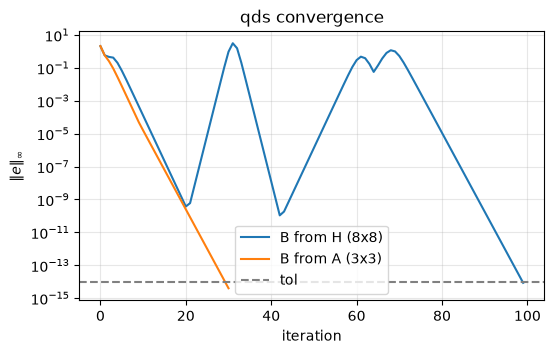

In [13]:
sv_A, it_A, hist_A = qds(np.diag(bidiag(A)), np.diag(bidiag(A), 1))   # directly on bidiag(A)
print(f"qds on bidiag(A): {sv_A}  ({it_A} iterations, error {np.abs(sv_A - s_true).max():.1e})")

plt.figure(figsize=(6, 3.5))
plt.semilogy(hist, label=f"B from H ({N}x{N})"); plt.semilogy(hist_A, label=f"B from A ({A.shape[1]}x{A.shape[1]})")
plt.axhline(1e-14, ls="--", color="gray", label="tol")
plt.xlabel("iteration"); plt.ylabel(r"$\|e\|_\infty$"); plt.title("qds convergence"); plt.legend(); plt.grid(alpha=.3); plt.show()

Linear convergence (rate $\sim (\sigma_{j+1}/\sigma_j)^2$): close singular values ⇒ slow convergence; shifts (dqds) are used in practice to speed it up.